<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/M4_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 103 Group 11 Assignment 2 - Milestone 4: Baseline Modeling, Evaluation & Data Generation Strategy

## Bike Share Station Demand for Growth Planning

### Members
- TODO: Add members here when ready to submit

## Part 1: Experimental Design & Data Preparation

### 1.1 Modeling Objective

**Problem Formulation:** Can we predict the hourly departures and arrivals at bike stations and classify whether the demand for a station is Low, Medium, or High, so that Bike Share Toronto can plan where to add new docks or stations?

**Target Variables:**

1. **Regression:** Departures per station per hour, Arrivals per station per hour during the peak months (May to October).
- For each month, a station is considered as open/operating if there is at least 1 trip starting at that station.
- For open/operating stations, hours with zero trips (ex. typical of night time hours) are included in the model.
- In Milestone 3, we set the following flags in the cleaned data to mark valid or invalid trips:
    - `flag_short`: Trip duration is under 60 seconds
    - `flag_long`: Trip duration is over 6 hours
    - `flag_no_end`: The trip has no `End_Station_Id`
    - `is_valid`: True when none of the flags is set, False if at least one is set
- (a) Departures - Valid trips (rows) have no `flag_short` or `flag_long` set. A missing end station doesn't matter.
- (b) Arrivals - Valid trips (rows) have none of the flags (`flag_short`, `flag_long`, `flag_no_end`) set.
    - Note: We said in Milestone 3 that we would no longer include Arrivals as a target variable due to the missing `End_Station_Id`s. However, after discussion, we have decided that the small percentage of missing `End_Station_Id`s should not affect the model too much, and this target variable is relevant in determining how busy a station is.

2. **Classification:** Predict the demand of stations during May-October 2025 as Low, Medium, or High, based on the training data from the same months in 2023 and 2024.
- One row is one station in one month. A station-month exists if the station had at least 1 valid departure in that month.
- Demand rate for a station is calculated by the average valid departures per operating day for this version.
    - An operating day is all the days in an operating month (if there is at least 1 valid departure in that month, all days in that month will be considered operating days). This is the same rule as we used for the Regression task, and we keep it here for consistency.
    - Days with no trips in an operating month will have a zero demand.
    - Valid departures use the same `is_valid` flag as in Milestone 3. Arrivals are not included in this rate.
    - Note: There are changes from Milestone 3, namely changing the definition to use operating days instead of the active days, because using active days only hides low-demand stations that may have few active days.
- The thresholds for the classification are the following:
    - Low: Less than 9.03
    - Medium: In between 9.03 - 35.81
    - High: Greater than 35.81
- Stations that first appear in 2025 have no 2023 to 2024 rate and are not in the classification data. They are used only in the business check that compares 2024 High stations with the new 2025 stations.
    

**Features:**

Each ML task has a different set of features.

1. **Regression**
- One row per station per hour
- (a) Features from date/timestamp:

     - `hour_of_day` - categorical values: hr_0-hr_23, rush hour will have different behaviour
     - `day_of_week` - categorical values: Monday(0)-Sunday(6), riding patterns are different on weekdays and weekends
     - `weekend_or_holiday` - flag (1 if weekend or holiday, 0 otherwise)
     - `year` - numerical values: 2023, 2024, 2025
     - `month` - categorical values: May-Oct

- (b) Features from weather (TBD)

    - `prec_mm_hr` - numerical value, precipitation/rain in that hour
    - `mean_temp_c_hr` - numerical value, temperature in that hour
    - `prec_mm_prev_hr` - numerical value, precipitation/rain in the previous hour (since people check weather before deciding to ride)

- (c) Features from station:

    - `station_id` - categorical
    - `new_station` - flag (1 if first month that the station is seen, 0 otherwise). We are doing regression on May to October months only, but we have data from January 2023. We will check for the first occurrence of a station since the very beginning of our data (January 2023) in order to set this flag. (Note that this information is in Milestone 3, since we cleaned the data using the entire dataset)


2. **Classification**

- One row per station per month (May to October)
- (a) Features from month's activity:
     - `monthly_volume` - numerical value, valid departures from the station in that month.
      - `was_flagged_new` - flag (1 if that month is the first month the station appears in the data, 0 otherwise). `is_new_start_station` flag from Milestone 3 on monthly level.

- (b) Features from station history (Milestone 3 station months)
    - `first_year` - numerical value, the year the station first appears in the data.
    - `first_month` - numerical value, the month the station first appears in the data.

### 1.2 Evaluation Criteria aligned with the Problem

Our training-validation-test split has been changed since Milestone 3:
- Training: May-October 2023 + May 2024
- Validation: June-October 2024
- Test: May-October 2025

We will score each model using the Validation set to help choose the best settings (hyperparameter tuning) and models. Once a model and/or its hyperparameter settings have been chosen, we will rerun the training on the Training+Validation set and evaluate this final model on the Test set once at the end.

1. **Regression** (departures per hour, arrivals per hour)
- Performance metrics: MAE, RMSE for departures and arrivals separately, since they are separate models.
- Baseline to compare against: average departures/arrivals for the same station, hour of day, and day of week in the training months.
- Success criteria: MAE on Test set should be lower than the baseline for both departures and arrivals.

2. **Classification**
- Performance metrics: TODO based on the Classification notebooks

3. **Business check**
- Compare the stations classified as High in 2024 with the stations that first appear in 2025, to see whether Bike Share Toronto's expansion followed the high-demand stations. This is to check whether our project's outputs would be useful for growth planning, according to the problem formulation we were trying to solve.

### 1.3 Preprocessing

This section builds the feature tables for the regression and classification models:
1. **Station-hour table** - For regression tasks (departures and arrivals): 1 row per station per hour. Features are departures, arrivals, time/calendar-related, weather, and new-station flag to mark if a station is new for that month.
2. **Station-month table** -- For classification task: 1 row per station per month. Features include **TODO: add based on classification notebook**

#### 1.3.1 Trip data

1. **Limit to peak season only (May to October months)** - Bike share demand is seasonal as we observed in Milestone 3 exploration. Since our business problem is to use our model to help determine areas of growth where new docks or bikes may be placed, we will limit our trip data to the most active summer months and include the months where activity begins to increase more each year as well we the months after summer when bike ridership slows down.

2. **Trip Validity** - Use the flags defined in Milestone 3: `flag_short`, `flag_long`, `flag_no_end`, and `is_valid`. (Refer to 1.1 Target Variables for the same definitions in this notebook) Since we are predicting departures and arrivals separately, counted trips for each regression task use the flags differently:
- **Departures** Using the start station: a trip counts as valid if it has neither `flag_short` nor `flag_long`. Missing end station doesn't matter for departures.
- **Arrivals** Using the End station: a trip counts as valid only if `is_valid` is true (this flag considers the `flag_no_end` as well as the other 2 flags and is true only if none of them are set).

In [ ]:
# Read file and set up dataframe

import os, glob, re, time
import numpy as np
import pandas as pd

# 1. Setup and paths (same pattern as the other notebooks)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"
    REFERENCE = f"{DATA}/reference"
    WEATHER_XLSX = f"{DATA}/bike_stations_hourly_weather_analyzed.xlsx"  # output of 03_testing_code.ipynb
else:
    DATA = "../data"
    REFERENCE = "../reference"
    WEATHER_XLSX = f"{DATA}/external/bike_stations_hourly_weather_analyzed.xlsx"

CLEAN = f"{DATA}/clean"
AGG = f"{DATA}/aggregate"
os.makedirs(AGG, exist_ok=True)

YEARS = [2023, 2024, 2025]
MONTHS = list(range(5, 11)) # May to October

def clean_file(year, month):
    return f"{CLEAN}/clean_ridership_{year}_{month:02d}.csv"

print("Clean files found:", sum(os.path.exists(clean_file(y, m)) for y in YEARS for m in MONTHS), "of", len(YEARS) * len(MONTHS))


USECOLS = ["Trip_Id", "Start_Time", "End_Time", "Start_Station_Id", "End_Station_Id",
           "flag_short", "flag_long", "flag_no_end", "is_valid"]

def read_clean(path):
    df = pd.read_csv(path, usecols=USECOLS, parse_dates=["Start_Time", "End_Time"],
                     dtype={"Start_Station_Id": "Int64", "End_Station_Id": "Int64"})
    df["start_hour"] = df["Start_Time"].dt.floor("h")
    df["end_hour"] = df["End_Time"].dt.floor("h")
    return df

## Aggregate departures and arrivals per station per hour in one month
def aggregate_month(df):
    dep_rows = df[~(df["flag_short"] | df["flag_long"])]
    dep = (dep_rows.groupby(["Start_Station_Id", "start_hour"]).size().rename("departures")
           .reset_index().rename(columns={"Start_Station_Id": "station_id", "start_hour": "hour_ts"}))
    arr_rows = df[df["is_valid"]]
    arr = (arr_rows.groupby(["End_Station_Id", "end_hour"]).size().rename("arrivals")
           .reset_index().rename(columns={"End_Station_Id": "station_id", "end_hour": "hour_ts"}))
    out = dep.merge(arr, on=["station_id", "hour_ts"], how="outer")
    out["departures"] = out["departures"].fillna(0).astype("int64")
    out["arrivals"] = out["arrivals"].fillna(0).astype("int64")
    return out

# Check on one month: the counts must add up to the trips we meant to count
jul23 = read_clean(clean_file(2023, 7))
sh = aggregate_month(jul23)
print(f"JULY 2023 Check - Trips in: {len(jul23):,}   station-hours out: {len(sh):,}")
print("Departures counted:", f"{sh['departures'].sum():,}", " trips not short/long:", f"{(~(jul23['flag_short'] | jul23['flag_long'])).sum():,}")
print("Arrivals counted:  ", f"{sh['arrivals'].sum():,}", " trips valid:         ", f"{jul23['is_valid'].sum():,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clean files found: 18 of 18
JULY 2023 Check - Trips in: 735,924   station-hours out: 288,233
Departures counted: 733,606  trips not short/long: 733,606
Arrivals counted:   733,428  trips valid:          733,428


#### 1.3.2 Station-hour table

1. **Include Zero-trip hours** - The group agreed to include hours with zero trips in operating months (ex. nighttime hours) because excluding them may give the model incorrect information about the true demand of a station. We build the the station-hour table for operating stations for every hour of the month. If there are missing hours, we assume that they are missing because there are no trips recorded in the dataset and the counts will be set to 0. (Same approach as Milestone 3. For this Milestone, we apply the same approach to arrivals.)

2. **Add Time-related columns from timestamps** - These are the following features needed for the regression tasks: `hour_of_day`, `day_of_week`, `year`, `month`. The `weekend_or_holiday` flag and other features not created directly from the timestamps will be added later.

In [ ]:
# Zero-trip hours
def add_zerotrip_hours(sh, year, month):
    hours = pd.date_range(f"{year}-{month:02d}-01", periods=pd.Period(f"{year}-{month:02d}").days_in_month * 24, freq="h")
    # trips can end in the next month; keep only hours inside this month so months do not overlap
    sh = sh[(sh["hour_ts"] >= hours[0]) & (sh["hour_ts"] <= hours[-1])]
    active = sh["station_id"].dropna().unique()
    grid = pd.MultiIndex.from_product([active, hours], names=["station_id", "hour_ts"]).to_frame(index=False)
    out = grid.merge(sh, on=["station_id", "hour_ts"], how="left")
    out["departures"] = out["departures"].fillna(0).astype("int64")
    out["arrivals"] = out["arrivals"].fillna(0).astype("int64")
    return out

full = add_zerotrip_hours(sh, 2023, 7)
print(f"Operating stations: {full['station_id'].nunique():,}  x  hours: {full['hour_ts'].nunique()}  =  rows: {len(full):,}")
print(f"Percentage of station-hours with zero departures: {(full['departures'] == 0).mean()*100:.1f}%")

# Time-related columns from timestamps
def add_calendar(df):
    ts = df["hour_ts"]
    df["hour_of_day"] = ts.dt.hour
    df["day_of_week"] = ts.dt.dayofweek
    df["year"] = ts.dt.year
    df["month"] = ts.dt.month
    return df

# Loop over May to October 2023 to 2025, check the counts, keep the tables for merging with weather data
# Note: The 2025 months (test set) go through the same preprocessing code but are not shown shown
year_parts, check_rows = {}, []
for y in YEARS:
    for m in MONTHS:
        trips = read_clean(clean_file(y, m))
        sh = add_calendar(add_zerotrip_hours(aggregate_month(trips), y, m))
        year_parts.setdefault(y, []).append(sh)
        check_rows.append({"year": y, "month": m,
                           "trips_for_departures": int((~(trips["flag_short"] | trips["flag_long"])).sum()),
                           "departures_in_table": int(sh["departures"].sum()),
                           "trips_valid": int(trips["is_valid"].sum()),
                           "arrivals_in_table": int(sh["arrivals"].sum()),
                           "stations": sh["station_id"].nunique(), "rows": len(sh)})
        if y < 2025:
            print(f"{y}-{m:02d}: {len(sh):>9,} station-hours, {sh['station_id'].nunique()} stations")

checks = pd.DataFrame(check_rows)
checks["departures_match"] = checks["trips_for_departures"] == checks["departures_in_table"]
checks["arrivals_in_next_month"] = checks["trips_valid"] - checks["arrivals_in_table"]
checks.to_csv(f"{AGG}/station_hour_checks.csv", index=False)

shown = checks[checks["year"] < 2025]
print("\nDepartures match the clean trip counts in every training and validation month:", shown["departures_match"].all())
print("Arrivals that fell into the next month:", f"{shown['arrivals_in_next_month'].sum():,}",
      f"of {shown['trips_valid'].sum():,} valid trips ({shown['arrivals_in_next_month'].sum()/shown['trips_valid'].sum()*100:.4f}%)")
shown

Operating stations: 681  x  hours: 744  =  rows: 506,664
Percentage of station-hours with zero departures: 54.2%
2023-05:   499,224 station-hours, 671 stations
2023-06:   483,840 station-hours, 672 stations
2023-07:   506,664 station-hours, 681 stations
2023-08:   518,568 station-hours, 697 stations
2023-09:   509,760 station-hours, 708 stations
2023-10:   546,096 station-hours, 734 stations
2024-05:   595,944 station-hours, 801 stations
2024-06:   586,080 station-hours, 814 stations
2024-07:   614,544 station-hours, 826 stations
2024-08:   627,192 station-hours, 843 stations
2024-09:   615,600 station-hours, 855 stations
2024-10:   634,632 station-hours, 853 stations

Departures match the clean trip counts in every training and validation month: True
Arrivals that fell into the next month: 1,830 of 9,033,231 valid trips (0.0203%)


,year,month,trips_for_departures,departures_in_table,trips_valid,arrivals_in_table,stations,rows,departures_match,arrivals_in_next_month
0,2023,5,587581,587581,587456,587330,671,499224,True,126
1,2023,6,661666,661666,661554,661339,672,483840,True,215
2,2023,7,733606,733606,733428,733298,681,506664,True,130
3,2023,8,757479,757479,757178,757016,697,518568,True,162
4,2023,9,751556,751556,751190,751024,708,509760,True,166
5,2023,10,598812,598812,598533,598479,734,546096,True,54
6,2024,5,684185,684185,683735,683527,801,595944,True,208
7,2024,6,764575,764575,763955,763802,814,586080,True,153
8,2024,7,902567,902567,902081,901893,826,614544,True,188
9,2024,8,904255,904255,903718,903497,843,627192,True,221


#### 1.3.3 Weather Data

**TODO: Writeup and code about the weather data**: Data source and weather stations, why Toronto City only, hourly download for May-October 2023-2025, and output file for 1.3.4.

1. **Source:** Environment and Climate Change Canada hourly readings, one row per hour (note that the time is in Local Standard Time and not Toronto time). Fields we kept: temperature, precipitation, etc. (please check this)
2. **Weather Stations used:** Considered Toronto City (31688), Toronto City Centre (48549), Toronto Island, Pearson. Which one we chose and why.

In [ ]:
#**3. TODO: Add the download code here, but add a check if the output file already exists or not:

if os.path.exists(WEATHER_XLSX):
    print("Weather file exists, download skipped: " , WEATHER_XLSX)
else:
    # Code to download goes here. remove the "pass" placeholder
    pass

4. Add short description of what the weather file contains.

#### 1.3.4 Weather join

1. **One row per hour** - The weather file created in 1.3.3 contains hourly Toronto City reading for every bike station. Since every station has the same reading, only the unique hours are needed before being joined.

2. **Timestamp conversion** - ECC Canada uses Local Standard Time, and does not include the daylight saving time change. Since we are using bike share data from the months of May to October (daylight savings time), we need to convert the weather timestamp to Toronto daylight savings time. For missing values in the weather, we use the data from the nearest hour preceding the hour with missing values.

3. **Previous-hour precipitation** - `prec_mm_prev_hr` is the precipitation of the previous hour. The first hour of May has no previous hour info in the table. This is set to 0 (no effect on the results).

4. The monthly tables from 1.3.2 are stacked and the weather columns are joined based on the hour. We kept only temperature, precipitation, and previous-hour precipitation.

In [ ]:
# Weather: one row per hour, in Toronto clock time, gaps filled within the season
wx = pd.read_excel(WEATHER_XLSX, sheet_name="hourly_bike_weather")
print(f"Weather file: {len(wx):,} rows, columns: {list(wx.columns)}")

if "wx_station_id" in wx.columns:
    wx = wx[wx["wx_station_id"] == 31688]                       # Toronto City
wx = (wx[["datetime", "temp_c", "precip_mm"]].drop_duplicates("datetime")
        .sort_values("datetime").reset_index(drop=True))

# LST is UTC-5 all year; Toronto clock time is UTC-4 in May to October
wx["hour_ts"] = (pd.to_datetime(wx["datetime"]).dt.tz_localize("Etc/GMT+5")
                   .dt.tz_convert("America/Toronto").dt.tz_localize(None))
wx = wx.drop(columns="datetime")
print(f"Unique hours in the weather file: {len(wx):,}")

# complete hourly index over the 18 months; fill gaps within each season, never from the previous October into May
idx = pd.DatetimeIndex(np.concatenate([pd.date_range(f"{y}-05-01", f"{y}-11-01", freq="h", inclusive="left") for y in YEARS]))
wx = wx.set_index("hour_ts").reindex(idx)
gaps = int(wx["temp_c"].isna().sum())
wx = wx.groupby(wx.index.year, group_keys=False).apply(lambda g: g.ffill().bfill()).rename_axis("hour_ts").reset_index()

# precipitation in the previous hour; the first hour of each May has no previous hour in the table and gets 0
wx["prec_mm_prev_hr"] = wx.groupby(wx["hour_ts"].dt.year)["precip_mm"].shift(1).fillna(0)
print("Hours with no reading, filled from the neighbouring hour:", gaps, "of", len(wx))

# Stack the 18 monthly grids and join the weather on the hour
grid = pd.concat([pd.concat(parts, ignore_index=True) for parts in year_parts.values()], ignore_index=True)
year_parts = None
grid = grid.astype({"station_id": "int32", "departures": "int16", "arrivals": "int16",
                    "hour_of_day": "int8", "day_of_week": "int8", "year": "int16", "month": "int8"})
grid = grid.merge(wx, on="hour_ts", how="left")

shown = grid[grid["year"] < 2025]
print(f"Station-hours in training and validation years: {len(shown):,}   rows without weather: {shown['temp_c'].isna().sum()}")
print(shown[["temp_c", "precip_mm", "prec_mm_prev_hr"]].describe().round(2).to_string())

Weather file: 1,000,000 rows, columns: ['station_id', 'short_name', 'name', 'bike_lat', 'bike_lon', 'wx_station_id', 'wx_name_x', 'wx_lat', 'wx_lon', 'datetime', 'temp_c', 'dew_point_temp_c', 'relative_humidity_pct', 'precip_mm', 'wind_spd_kmh', 'wx_name_y']
Unique hours in the weather file: 15,408
Hours with no reading, filled from the neighbouring hour: 20 of 13248
Station-hours in training and validation years: 6,738,144   rows without weather: 0
           temp_c   precip_mm  prec_mm_prev_hr
count  6738144.00  6738144.00       6738144.00
mean        18.47        0.10             0.10
std          5.30        0.95             0.95
min          0.50        0.00             0.00
25%         15.20        0.00             0.00
50%         19.10        0.00             0.00
75%         22.20        0.00             0.00
max         32.80       45.00            45.00


#### 1.3.5 Model Features

This section builds the feature set for the regression tasks (as described in 1.1).
- `hour_of_day`, `day_of_week`, `month`, `year`: Already available from 1.3.2 . The `day_of_week` is 0-6 but is used as a code (categorical) and not a numerical variable. `year` is numerical, and `hour_of_day` and `month` are also categorical.
- `weekend_or_holiday`: (flag) 1 on Saturdays and Sundays and the following holidays agreed on by our group: Canada Day, Civic Holiday, Labour Day
- `temp_c`, `precip_mm`, `prec_mm_prev_hr`: Already available from 1.3.4
- `station_id`: categorical. One-hot encode for the model
- `new_station`: (flag) 1 for every hour of the first month of a station (starting from January 2023)

Of the above features, we need to build the following:
- `weekend_or_holiday`
- `new_station`

In [ ]:
# Weekend-or-holiday flag
HOLIDAYS = pd.to_datetime([
    "2023-07-01", "2023-08-07", "2023-09-04",     # Canada Day, Civic Holiday, Labour Day
    "2024-07-01", "2024-08-05", "2024-09-02",
    "2025-07-01", "2025-08-04", "2025-09-01",
])
is_weekend = grid["day_of_week"] >= 5
is_holiday = grid["hour_ts"].dt.normalize().isin(HOLIDAYS)
grid["weekend_or_holiday"] = (is_weekend | is_holiday).astype("int8")

# New-station flag from the first month each station appears in the data (from January 2023)
first_seen = pd.read_csv(f"{REFERENCE}/station_first_seen.csv", usecols=["station_id", "first_seen"])
first_seen["station_id"] = first_seen["station_id"].astype("int32")
first_seen["first_month"] = pd.to_datetime(first_seen["first_seen"]).dt.to_period("M")
grid = grid.merge(first_seen[["station_id", "first_month"]], on="station_id", how="left")
no_record = grid["first_month"].isna()
fallback = grid.loc[no_record].groupby("station_id")["hour_ts"].min().dt.to_period("M")
grid.loc[no_record, "first_month"] = grid.loc[no_record, "station_id"].map(fallback)
grid["new_station"] = (grid["hour_ts"].dt.to_period("M") == grid["first_month"]).astype("int8")
grid = grid.drop(columns="first_month")

shown = grid[grid["year"] < 2025]
print(f"Percentage of station-hours flagged weekend or holiday (2023-2024): {shown['weekend_or_holiday'].mean()*100:.1f}%")
print("Stations with no first-seen record, first month in this table used:", sorted(fallback.index.tolist()))
print("Stations flagged new, by month (2023-2024):")
print(shown[shown["new_station"] == 1].groupby(["year", "month"])["station_id"].nunique().to_string())

Percentage of station-hours flagged weekend or holiday (2023-2024): 29.7%
Stations with no first-seen record, first month in this table used: [7763, 8140]
Stations flagged new, by month (2023-2024):
year  month
2023  5        10
      6         4
      7        10
      8        21
      9        11
      10       26
2024  5         3
      6        13
      7        12
      8        18
      9        15


#### 1.3.6 Three-way Split (Training, Validation, Test Sets)

- Training: May-October 2023 + May 2024
- Validation: June-October 2024
- Test: May-October 2025

In [ ]:
# Three-way split and then save to a parquet file so preprocessing does not have to be redone for each model
PROCESSED = f"{DATA}/processed"
os.makedirs(PROCESSED, exist_ok=True)
OUT_FILE = f"{PROCESSED}/regression_station_hour_may_oct.parquet"

conditions = [
    (grid["year"] == 2023) | ((grid["year"] == 2024) & (grid["month"] == 5)),
    (grid["year"] == 2024) & (grid["month"] >= 6),
    (grid["year"] == 2025),
]
grid["split"] = np.select(conditions, ["train", "val", "test"], default="drop")
assert (grid["split"] != "drop").all()

COLUMNS = ["station_id", "hour_ts", "split",
           "hour_of_day", "day_of_week", "weekend_or_holiday", "year", "month",
           "temp_c", "precip_mm", "prec_mm_prev_hr",
           "new_station",
           "departures", "arrivals"]
grid = grid[COLUMNS]
grid.to_parquet(OUT_FILE, index=False)

summary = grid[grid["split"] != "test"].groupby("split")["station_id"].agg(rows="size", stations="nunique")
print(summary.to_string())
print("test : written, not inspected until Part 4")
print(f"\nSaved {grid.shape[1]} columns to {OUT_FILE}")

          rows  stations
split                   
train  3660096       826
val    3078048       863
test : written, not inspected until Part 4

Saved 14 columns to /content/drive/MyDrive/DataSets/processed/regression_station_hour_may_oct.parquet


#### 1.3.7 Classification Table


In [32]:
import calendar

DEMAND_LABELS = ["Low", "Medium", "High"]
LABEL_MAP = {"Low": 0, "Medium": 1, "High": 2}
CLS_OUT_FILE = f"{PROCESSED}/classification_station_month_may_oct.parquet"

# 1. Aggregate valid departures per station per month (May-Oct 2023-2025)
monthly_samples = []
for y in YEARS:
    for m in MONTHS:
        df = pd.read_csv(
            clean_file(y, m),
            usecols=["Start_Station_Id", "flag_short", "flag_long"],
            dtype={"Start_Station_Id": "Int64"}
        )
        # Valid departures: neither flag_short nor flag_long (missing end station allowed)
        valid_dep = df[~(df["flag_short"] | df["flag_long"])].dropna(subset=["Start_Station_Id"])

        monthly_stats = (
            valid_dep.groupby("Start_Station_Id")
            .size()
            .rename("monthly_volume")
            .reset_index()
            .rename(columns={"Start_Station_Id": "station_id"})
        )
        monthly_stats["station_id"] = monthly_stats["station_id"].astype("int32")
        monthly_stats["year"] = y
        monthly_stats["month"] = m
        monthly_stats["days_in_month"] = calendar.monthrange(y, m)[1]
        monthly_samples.append(monthly_stats)

cls_df = pd.concat(monthly_samples, ignore_index=True)

# 2. Add station history features (first_year, first_month, was_flagged_new)
first_seen = pd.read_csv(f"{REFERENCE}/station_first_seen.csv", usecols=["station_id", "first_seen"])
first_seen["station_id"] = first_seen["station_id"].astype("int32")
first_seen_dt = pd.to_datetime(first_seen["first_seen"])
first_seen["first_year"] = first_seen_dt.dt.year
first_seen["first_month"] = first_seen_dt.dt.month

cls_df = cls_df.merge(first_seen[["station_id", "first_year", "first_month"]], on="station_id", how="left")

# Fallback if station is missing from reference table
missing_mask = cls_df["first_year"].isna()
if missing_mask.any():
    fallback = cls_df.loc[missing_mask].groupby("station_id")[["year", "month"]].min()
    cls_df.loc[missing_mask, "first_year"] = cls_df.loc[missing_mask, "station_id"].map(fallback["year"])
    cls_df.loc[missing_mask, "first_month"] = cls_df.loc[missing_mask, "station_id"].map(fallback["month"])

cls_df["first_year"] = cls_df["first_year"].astype("int16")
cls_df["first_month"] = cls_df["first_month"].astype("int8")
cls_df["was_flagged_new"] = (
    (cls_df["year"] == cls_df["first_year"]) & (cls_df["month"] == cls_df["first_month"])
).astype("int8")

# Exclude stations that first appear in 2025 (used only for Business Check)
cls_df = cls_df[cls_df["first_year"] < 2025].copy()

# 3. Assign temporal splits
conditions = [
    (cls_df["year"] == 2023) | ((cls_df["year"] == 2024) & (cls_df["month"] == 5)),
    (cls_df["year"] == 2024) & (cls_df["month"] >= 6),
    (cls_df["year"] == 2025),
]
cls_df["split"] = np.select(conditions, ["train", "val", "test"], default="drop")
assert (cls_df["split"] != "drop").all()

# 4. Calculate demand rate & quantile cutoffs strictly on TRAINING data
train_rates = (
    cls_df[cls_df["split"] == "train"]
    .groupby("station_id")
    .agg(total_departures=("monthly_volume", "sum"), operating_days=("days_in_month", "sum"))
    .reset_index()
)
train_rates["demand_rate"] = train_rates["total_departures"] / train_rates["operating_days"]

c1, c2 = np.quantile(train_rates["demand_rate"], [1/3, 2/3])
print(f"Training Demand Rate Cutoffs -> Low: <= {c1:.2f} | Medium: <= {c2:.2f} | High: > {c2:.2f} trips/day")

train_rates["demand_class"] = pd.cut(
    train_rates["demand_rate"],
    bins=[-np.inf, c1, c2, np.inf],
    labels=DEMAND_LABELS
).astype(str)
train_rates["target"] = train_rates["demand_class"].map(LABEL_MAP)

# Inner merge ensures only stations present in training are kept
cls_df = cls_df.merge(train_rates[["station_id", "target"]], on="station_id", how="inner")

CLS_COLUMNS = ["station_id", "year", "month", "split",
               "monthly_volume", "was_flagged_new", "first_year", "first_month", "target"]
cls_df = cls_df[CLS_COLUMNS]
cls_df.to_parquet(CLS_OUT_FILE, index=False)

summary = cls_df[cls_df["split"] != "test"].groupby("split")["station_id"].agg(rows="size", stations="nunique")
print(summary.to_string())
print("test : written, not inspected until Part 3/4")
print(f"\nSaved {cls_df.shape[1]} columns to {CLS_OUT_FILE}")


Training Demand Rate Cutoffs -> Low: <= 9.03 | Medium: <= 35.81 | High: > 35.81 trips/day
       rows  stations
split                
train  4956       824
val    3993       805
test : written, not inspected until Part 3/4

Saved 9 columns to /content/drive/MyDrive/DataSets/processed/classification_station_month_may_oct.parquet


### 1.4 Validation and Leakage

How we split the data into Training, Validation, and Testing sets was described in earlier sections (1.2, 1.3.6).

These are the rules and decisions we made regarding how we validate the models and also how we prevent data leakage.

1. The data split was based on 3 factors:

    - (1) Only 2 years of training/validation data (2023-2024)
    - (2) Using only the peak or most active months of the year (May-Oct)
    - (3) That our dataset is time-based and a random or stratified split would cause data leakage since rows from later months would end up in the training data.

    - Therefore, we split it by timestamp. The training set is May-October 2023 to get the patterns for one year, and May 2024 is included so that the potential growth trend (May 2023 to May 2024) can be learned. We're aware that this is a limitation on our training data, since there's no guarantee that the growth observed from just 1 month over 2 years will be the same growth for the other months or even be similar growth for future months and years.
  
2. We will use the validation set to tune and select our model. After the model is chosen, we will rerun training on the full Training+Validation data. This final model will be run the on the test set only once.

3. Cut-offs, thresholds, regression baseline averages, and scalers used are based on training data only.

4. The Test set (2025 months) are preprocessed similarly to the Training and Validation but not displayed or checked. It is kept hidden away until final evaluation.

5. Weather is joined only using the current and previous hour's values. No weather from later hours is included for any row.

## Part 2: Data Generation / Augmentation (If Applicable)

Our project does not need data generation or augmentation.
1. For Regression tasks - Even though there are many zero-trip hours in the feature set, that is an actual observation for those hours for nighttime or for very low-demand stations. The zeros are real information about those hours and stations and it is useful for the business problem (planning based on how much demand is at stations). The prediction should show zero as well for those hours.
2. For Classification task - We defined the Low, Medium, and High cutoffs as the lower, middle, and upper thirds of the training data, so classes are closely equal in size (no class imbalance).
3. The dataset is already several million rows, so there is more than enough data and we don't need to generate more synthetic data for training or test.
4. Stations added in 2025 may cause problems for our models since they would not exist at all in the training or validation data. For the classification task, the group decided to exclude these stations and use them in the business check instead (see Evaluation Criteria).

## Part 3: Final Model Development & Optimization

1. **Regression: Departures**

2. **Regression: Arrivals**

3. **Classification: Low/Medium/High Demand**

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load preprocessed classification table
cls_data = pd.read_parquet(f"{PROCESSED}/classification_station_month_may_oct.parquet")

FEATURES = ["monthly_volume", "was_flagged_new", "first_year", "first_month"]
DEMAND_LABELS = ["Low", "Medium", "High"]

train_df = cls_data[cls_data["split"] == "train"]
val_df = cls_data[cls_data["split"] == "val"]
test_df = cls_data[cls_data["split"] == "test"]

X_train_raw, y_train = train_df[FEATURES], train_df["target"]
X_val_raw, y_val = val_df[FEATURES], val_df["target"]
X_test_raw, y_test = test_df[FEATURES], test_df["target"]

# -------------------------------------------------------------
# STEP 1: TRAIN & COMPARE ON VALIDATION SET
# -------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)

log_reg = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

knn = KNeighborsClassifier(n_neighbors=5, weights="uniform")
knn.fit(X_train_scaled, y_train)

for name, model in [("Logistic Regression", log_reg), ("k-Nearest Neighbors (k=5)", knn)]:
    print(f"\n==================== {name.upper()} (TRAIN vs. VAL) ====================")
    for X_split, y_split, split_name in [(X_train_scaled, y_train, "Train"), (X_val_scaled, y_val, "Validation")]:
        preds = model.predict(X_split)
        print(f"--- {split_name} Accuracy: {accuracy_score(y_split, preds):.4f} ---")
        print(classification_report(y_split, preds, target_names=DEMAND_LABELS, zero_division=0))

# -------------------------------------------------------------
# STEP 2: RETRAIN ON TRAIN + VALIDATION & EVALUATE ON TEST SET
# -------------------------------------------------------------
print("\n==================== FINAL TEST EVALUATION (TRAIN+VAL -> TEST) ====================")
X_trainval_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
y_trainval = pd.concat([y_train, y_val], ignore_index=True)

final_scaler = StandardScaler()
X_trainval_scaled = final_scaler.fit_transform(X_trainval_raw)
X_test_scaled = final_scaler.transform(X_test_raw)

final_log_reg = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
final_log_reg.fit(X_trainval_scaled, y_trainval)

final_knn = KNeighborsClassifier(n_neighbors=5, weights="uniform")
final_knn.fit(X_trainval_scaled, y_trainval)

for name, model in [("Logistic Regression", final_log_reg), ("k-Nearest Neighbors (k=5)", final_knn)]:
    test_preds = model.predict(X_test_scaled)
    print(f"\n--- Final Test Set: {name} ---")
    print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f}")
    print(classification_report(y_test, test_preds, target_names=DEMAND_LABELS, zero_division=0))



==================== LOGISTIC REGRESSION (TRAIN vs. VAL) ====================
--- Train Accuracy: 0.9171 ---
              precision    recall  f1-score   support

         Low       0.92      0.95      0.94      1399
      Medium       0.89      0.87      0.88      1740
        High       0.94      0.93      0.94      1817

    accuracy                           0.92      4956
   macro avg       0.92      0.92      0.92      4956
weighted avg       0.92      0.92      0.92      4956

--- Validation Accuracy: 0.8765 ---
              precision    recall  f1-score   support

         Low       0.95      0.90      0.92      1354
      Medium       0.84      0.77      0.81      1316
        High       0.84      0.96      0.90      1323

    accuracy                           0.88      3993
   macro avg       0.88      0.88      0.88      3993
weighted avg       0.88      0.88      0.88      3993


==================== K-NEAREST NEIGHBORS (K=5) (TRAIN vs. VAL) ====================
--- Tra

## Part 4: Model Evaluation & Analytical Depth

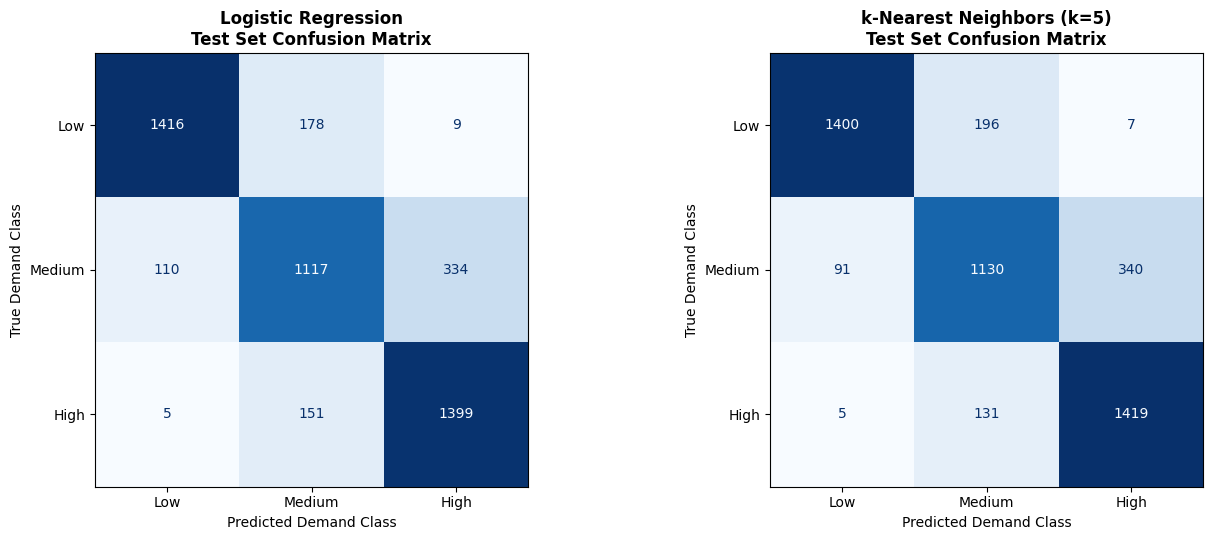

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize

models = [
    ("Logistic Regression", final_log_reg),
    ("k-Nearest Neighbors (k=5)", final_knn)
]

# -------------------------------------------------------------
# 1. SIDE-BY-SIDE CONFUSION MATRICES (TEST SET)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (name, model) in zip(axes, models):
    preds = model.predict(X_test_scaled)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        preds,
        display_labels=DEMAND_LABELS,
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"{name}\nTest Set Confusion Matrix", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Demand Class")
    ax.set_ylabel("True Demand Class")

plt.tight_layout()
plt.show()




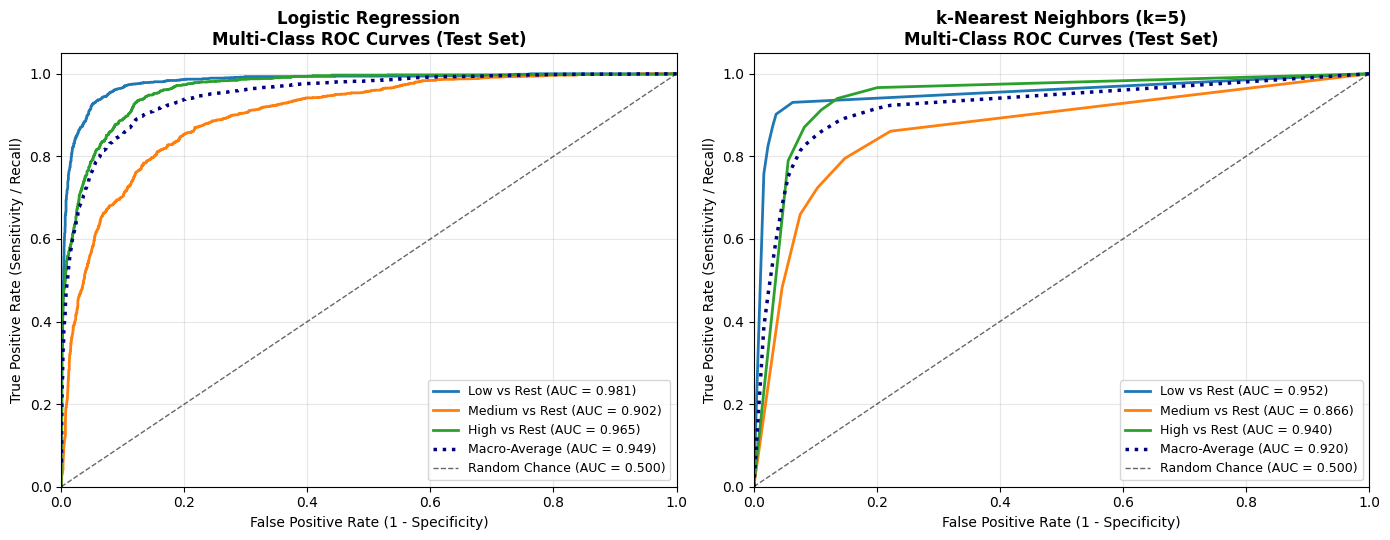

In [35]:
# -------------------------------------------------------------
# 2. MULTI-CLASS ROC CURVES (ONE-VS-REST ON TEST SET)
# -------------------------------------------------------------
# Binarize true labels into [0, 1, 2] columns for One-vs-Rest ROC curves
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = len(DEMAND_LABELS)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (name, model) in zip(axes, models):
    y_score = model.predict_proba(X_test_scaled)

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        ax.plot(
            fpr[i], tpr[i],
            color=colors[i],
            lw=2,
            label=f"{DEMAND_LABELS[i]} vs Rest (AUC = {roc_auc[i]:.3f})"
        )

    # Compute Macro-Average ROC curve & AUC
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    macro_auc = auc(all_fpr, mean_tpr)

    ax.plot(
        all_fpr, mean_tpr,
        color="navy", linestyle=":", linewidth=2.5,
        label=f"Macro-Average (AUC = {macro_auc:.3f})"
    )

    # Diagonal random-guess reference line
    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Random Chance (AUC = 0.500)")

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate (1 - Specificity)")
    ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
    ax.set_title(f"{name}\nMulti-Class ROC Curves (Test Set)", fontsize=12, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Part 5: Analytical Reflection (1 Page Required-Very important)